# Etapa 5 — A Alternativa Probabilística

Este é o centro do projeto: em vez de um ponto, entregar uma **distribuição preditiva calibrada** do que o Focus projeta. As Etapas 3 e 4 estabelecem o terreno:

- **Etapa 3:** o intervalo construído com o desvio-padrão publicado cobre, na mediana, **40%** quando declara 90% — mas a dispersão **ordena bem** a incerteza relativa (Spearman positivo em 19/20 casos). Erra a *escala*.
- **Etapa 4:** o **ponto** não é corrigível de forma estável (de 56 comparações confiáveis, 2 melhoram — o mesmo episódio — e 11 pioram).

Logo o ganho possível está no segundo momento. Mas *qual* é a melhor forma de capturá-lo?

## A escada — cada degrau só entra na entrega final se provar seu valor

Existe um concorrente simples e provavelmente forte que o plano original não previa: **reescalar o próprio σ do Focus**. Por isso a avaliação é uma escada, e cada degrau precisa **superar o anterior fora da amostra**:

| Degrau | O que é | O que acrescenta |
|---|---|---|
| **B0** | `Normal(0, σ)` com o σ **publicado** | o que um usuário do boletim faria hoje |
| **B0′** | o mesmo σ × `k(indicador, horizonte)` | corrige a **escala** (concorrente honesto) |
| **B1** | quantis históricos do erro | corrige **forma e viés**, mas com largura fixa |
| **B2** | XGBoost quantílico (multi-quantil) | largura **condicional ao estado macro** |
| **B3** | CQR (regressão quantílica conformalizada) | **garantia de cobertura** em amostra finita |

**Regra de decisão:** um degrau só é recomendado se superar o anterior em CRPS fora da amostra *de forma robusta* — isto é, sem depender de um único episódio, como o ganho aparente do IGP-M na Etapa 4.

## Como avaliar uma distribuição

MAE/RMSE respondem à pergunta errada aqui: premiam quem acerta o centro e são cegos a quem declara honestamente a incerteza. Usamos regras de pontuação **próprias** (`src/focus/scores.py`, com testes):

- **CRPS** (aproximado pela decomposição quantílica) — o "MAE das distribuições"; só é minimizado pela densidade verdadeira.
- **Cobertura empírica** do intervalo de 90%, marginal **e por regime**.
- **Largura** (*sharpness*) — só se lê junto com a cobertura: um intervalo estreito que não cobre nada não vale nada.
- **Diebold-Mariano** sobre o CRPS por observação, entre degraus consecutivos.

## Uma ressalva que precisa ser dita antes dos resultados

A garantia de cobertura do conformal exige **permutabilidade** entre os erros de calibração e os de teste. Séries macro com mudança de regime a violam: o erro de 2020 não é "permutável" com o de 2010. Por isso **não tratamos a garantia como teorema aplicável** — medimos a cobertura *empírica* fora da amostra, com atenção especial aos regimes de virada, que é onde um intervalo mais importa.

## Roteiro

1. Configuração e treino da escada (validação aninhada, purgada por data)
2. Resultado: CRPS, cobertura e largura por degrau
3. Cada degrau se paga? Diebold-Mariano entre degraus consecutivos
4. Robustez: o ganho sobrevive sem um único episódio?
5. Cobertura por regime — o teste que importa
6. Adaptive Conformal Inference: resolve a deriva?
7. Conclusões

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

RAIZ_PROJETO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ_PROJETO / "src"))

from focus.configuracao import DIR_PROCESSADO, HORIZONTES_MESES
from focus.armazenamento import carregar_dataset
from focus.calibracao import teste_kupiec
from focus.conformal import (
    aci_intervalos, cqr_multiplos_niveis, escores_cqr, ordenar_quantis, quantil_conformal,
)
from focus.dm_test import diebold_mariano
from focus.features_ml import preparar_matriz_features
from focus.probabilistico import (
    TAUS_PADRAO, ajustar_fator_sigma, quantis_historicos, quantis_normais,
)
from focus.scores import cobertura, crps_por_linha, interval_score
from focus.splits import folds_seguros, separar_fit_val

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

TAUS = list(TAUS_PADRAO)
J05, J95 = TAUS.index(0.05), TAUS.index(0.95)
J25, J75 = TAUS.index(0.25), TAUS.index(0.75)
EMBARGO = max(HORIZONTES_MESES)          # 12 meses
ORDEM = ["ipca", "cambio", "igpm", "selic", "desocupacao"]
ROTULO = {"ipca": "IPCA", "cambio": "Câmbio", "igpm": "IGP-M", "desocupacao": "Desocupação", "selic": "Selic"}
COL_DATA = {n: "referencia_periodo" for n in ORDEM} | {"selic": "data_reuniao"}
N_FOLDS = {n: 5 for n in ORDEM} | {"desocupacao": 3}
METODOS = ["B0", "B0k", "B1", "B2", "B3"]
NOME_METODO = {"B0": "B0  σ publicado", "B0k": "B0′ σ×k", "B1": "B1  quantis hist.",
               "B2": "B2  XGB quantílico", "B3": "B3  CQR"}

paineis = {n: carregar_dataset(DIR_PROCESSADO, f"painel_{n}").reset_index(drop=True) for n in ORDEM}
print({ROTULO[n]: len(p) for n, p in paineis.items()})

{'IPCA': 970, 'Câmbio': 970, 'IGP-M': 970, 'Selic': 648, 'Desocupação': 214}


## 1. Configuração e treino da escada

Tudo é estimado com validação cruzada **aninhada e purgada por data** (embargo de 12 meses, o maior horizonte), como na Etapa 4: nenhum desfecho usado para ajustar um degrau pode ser posterior ao instante em que qualquer previsão de teste foi emitida.

Trabalhamos no **espaço do erro** (`erro = realizado − mediana`): a distribuição preditiva do nível é `mediana + quantis(erro)`, e a perda pinball é invariante a essa translação.

**Detalhes de desenho que importam:**

- **B0′ e B1 são estimados por horizonte**, só com o treino de cada fold.
- **B3 é "Mondrian" por horizonte:** a correção conformal `Q` é calculada separadamente para cada horizonte, para que a garantia valha *condicional ao horizonte* (a escala do erro muda muito entre `h=1` e `h=12`).
- **B3 usa um split temporal em três partes** dentro de cada treino externo: ajuste → *(embargo de 12m)* → calibração. A calibração é a fatia **mais recente**, o que captura melhor o regime vigente sob deriva.
- Quantis cruzados de B2/B3 são reordenados (rearranjo monótono).
- Se a amostra de calibração for pequena demais para dar uma garantia finita a algum nível (`n < 9` por horizonte), B3 fica **indisponível** naquele fold — não é forçado.
- Folds com treino insuficiente para um horizonte deixam o degrau **indisponível**, e a comparação é feita apenas na **amostra comum** a todos os degraus.

In [2]:
PARAMS_XGB_Q = dict(
    objective="reg:quantileerror", quantile_alpha=np.array(TAUS), n_estimators=800, max_depth=2,
    learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, min_child_weight=5, reg_lambda=2.0,
    early_stopping_rounds=40, eval_metric="quantile", random_state=42,
)
PARAMS_XGB_Q_SEM_ES = {k: v for k, v in PARAMS_XGB_Q.items()
                       if k not in ("early_stopping_rounds", "eval_metric")} | {"n_estimators": 60}


def treinar_quantilico(X, y, datas):
    sep = separar_fit_val(datas.reset_index(drop=True), 3)
    if sep is None:
        return xgb.XGBRegressor(**PARAMS_XGB_Q_SEM_ES).fit(X, y)
    fit, val = sep
    return xgb.XGBRegressor(**PARAMS_XGB_Q).fit(
        X.iloc[fit], y[fit], eval_set=[(X.iloc[val], y[val])], verbose=False)


def rodar_escada(nome):
    p = paineis[nome]
    X, _ = preparar_matriz_features(p, incluir_horizonte=True)
    y = p["erro_focus"].to_numpy()
    h = p["horizonte"].to_numpy()
    sd = p["desvio_padrao_focus"].to_numpy()
    d = p[COL_DATA[nome]]
    n = len(y)

    Q = {m: np.full((n, len(TAUS)), np.nan) for m in METODOS}
    fold_id = np.full(n, -1)
    # por (horizonte, fold): modelo base e escores de calibracao, para o ACI
    cache_aci = []
    best_iters = []

    for f, (tr, te) in enumerate(folds_seguros(d, N_FOLDS[nome], EMBARGO)):
        fold_id[te] = f
        Q["B0"][te] = quantis_normais(sd[te], TAUS, 1.0)

        for hh in HORIZONTES_MESES:
            mt, ms = tr[h[tr] == hh], te[h[te] == hh]
            if len(ms) == 0:
                continue
            try:                                            # B0': fator k por horizonte
                k = ajustar_fator_sigma(y[mt], sd[mt], TAUS)
                Q["B0k"][ms] = quantis_normais(sd[ms], TAUS, k)
            except ValueError:
                pass
            if len(mt) >= 5:                                # B1: quantis historicos
                Q["B1"][ms] = quantis_historicos(y[mt], len(ms), TAUS)

        # B2: XGBoost quantilico no treino externo inteiro
        m2 = treinar_quantilico(X.iloc[tr], y[tr], d.iloc[tr])
        best_iters.append(int(getattr(m2, "best_iteration", -1)))
        Q["B2"][te] = ordenar_quantis(m2.predict(X.iloc[te]))

        # B3: CQR Mondrian por horizonte (proper | embargo | calibracao)
        fs = folds_seguros(d.iloc[tr].reset_index(drop=True), 3, EMBARGO)
        if not fs:
            continue
        proper, cal = tr[fs[-1][0]], tr[fs[-1][1]]
        m3 = treinar_quantilico(X.iloc[proper], y[proper], d.iloc[proper])
        q_cal = ordenar_quantis(m3.predict(X.iloc[cal]))
        q_te = ordenar_quantis(m3.predict(X.iloc[te]))
        for hh in HORIZONTES_MESES:
            ic, it = np.flatnonzero(h[cal] == hh), np.flatnonzero(h[te] == hh)
            if len(ic) < 9 or len(it) == 0:                 # sem garantia finita a 90%
                continue
            ajustado = cqr_multiplos_niveis(q_cal[ic], y[cal][ic], q_te[it], TAUS)
            if np.isfinite(ajustado).all():
                Q["B3"][te[it]] = ajustado
            cache_aci.append({
                "fold": f, "h": hh, "idx_te": te[it],
                "q_inf": q_te[it][:, J05], "q_sup": q_te[it][:, J95],
                "escores": escores_cqr(q_cal[ic][:, J05], q_cal[ic][:, J95], y[cal][ic]),
            })

    return {"y": y, "h": h, "sd": sd, "datas": d, "t_dec": p["data_travamento"],
            "Q": Q, "fold": fold_id, "aci": cache_aci, "best_iters": best_iters}


escada = {n: rodar_escada(n) for n in ORDEM}

for n in ORDEM:
    r = escada[n]
    disp = {m: int(np.isfinite(r["Q"][m]).all(axis=1).sum()) for m in METODOS}
    print(f"{ROTULO[n]:<12} linhas={len(r['y']):>4} | disponíveis: {disp} | iterações do B2 por fold: {r['best_iters']}")

IPCA         linhas= 970 | disponíveis: {'B0': 824, 'B0k': 824, 'B1': 824, 'B2': 824, 'B3': 660} | iterações do B2 por fold: [799, 170, 14, 0, 0]
Câmbio       linhas= 970 | disponíveis: {'B0': 824, 'B0k': 824, 'B1': 824, 'B2': 824, 'B3': 660} | iterações do B2 por fold: [799, 16, 31, 0, 0]
IGP-M        linhas= 970 | disponíveis: {'B0': 824, 'B0k': 824, 'B1': 824, 'B2': 824, 'B3': 660} | iterações do B2 por fold: [0, 76, 41, 0, 101]
Selic        linhas= 648 | disponíveis: {'B0': 552, 'B0k': 552, 'B1': 552, 'B2': 552, 'B3': 444} | iterações do B2 por fold: [0, 0, 0, 261, 124]
Desocupação  linhas= 214 | disponíveis: {'B0': 176, 'B0k': 120, 'B1': 120, 'B2': 176, 'B3': 64} | iterações do B2 por fold: [-1, 2, 799]


**`iterações do B2 por fold`** é um diagnóstico importante: valores próximos de 0 significam que o XGBoost quantílico não encontra **nenhuma** iteração que melhore a validação — ele degenera para "pouco além dos quantis incondicionais". Isso já antecipa o resultado dos degraus B2/B3.

## 2. Resultado: CRPS, cobertura e largura

Todas as métricas na **amostra comum** a todos os degraus disponíveis por indicador — comparar degraus em amostras diferentes seria injusto. O *skill* é `1 − CRPS / CRPS(B0)`: positivo = melhor que o σ publicado.

In [3]:
def amostra_comum(nome):
    Q = escada[nome]["Q"]
    metodos = [m for m in METODOS if np.isfinite(Q[m]).all(axis=1).sum() >= 30]
    mask = np.all([np.isfinite(Q[m]).all(axis=1) for m in metodos], axis=0)
    return metodos, mask


linhas = []
for n in ORDEM:
    r = escada[n]
    metodos, mask = amostra_comum(n)
    if mask.sum() == 0:
        continue
    y = r["y"][mask]
    crps0 = crps_por_linha(y, r["Q"]["B0"][mask], TAUS).mean()
    for m in metodos:
        q = r["Q"][m][mask]
        crps = crps_por_linha(y, q, TAUS).mean()
        linhas.append({
            "indicador": ROTULO[n], "método": NOME_METODO[m], "n": int(mask.sum()),
            "CRPS": crps, "skill vs B0 (%)": 100 * (1 - crps / crps0),
            "cobertura 90%": cobertura(y, q[:, J05], q[:, J95]),
            "cobertura 50%": cobertura(y, q[:, J25], q[:, J75]),
            "largura 90%": float(np.mean(q[:, J95] - q[:, J05])),
            "interval score 90%": interval_score(y, q[:, J05], q[:, J95], alpha=0.10),
        })
tabela = pd.DataFrame(linhas)
display(tabela.set_index(["indicador", "método"]).round(3))

n   CRPS  skill vs B0 (%)  cobertura 90%  \
indicador   método                                                           
IPCA        B0  σ publicado     660  0.216            0.000          0.435   
            B0′ σ×k             660  0.196            9.075          0.792   
            B1  quantis hist.   660  0.196            9.377          0.759   
            B2  XGB quantílico  660  0.196            9.142          0.745   
            B3  CQR             660  0.197            8.675          0.809   
Câmbio      B0  σ publicado     660  0.246            0.000          0.509   
            B0′ σ×k             660  0.227            7.907          0.832   
            B1  quantis hist.   660  0.242            1.670          0.723   
            B2  XGB quantílico  660  0.243            1.177          0.802   
            B3  CQR             660  0.261           -5.975          0.748   
IGP-M       B0  σ publicado     660  0.614            0.000          0.306   
            B0′ σ×k             660  0.535           12.876          0.806   
            B1  quantis hist.   660  0.549           10.559          0.741   
            B2  XGB quantílico  660  0.544           11.481          0.742   
            B3  CQR             660  0.519           15.540          0.832   
Selic       B0  σ publicado     444  0.716            0.000          0.579   
            B0′ σ×k             444  0.645            9.992          0.813   
            B1  quantis hist.   444  0.666            7.005          0.885   
            B2  XGB quantílico  444  0.737           -2.944          0.860   
            B3  CQR             444  0.711            0.771          0.874   
Desocupação B0  σ publicado      64  0.722            0.000          0.406   
            B0′ σ×k              64  0.594           17.718          0.969   
            B1  quantis hist.    64  0.383           46.951          0.859   
            B2  XGB quantílico   64  0.240           66.713          0.797   
            B3  CQR              64  0.396           45.107          0.750   

                                cobertura 50%  largura 90%  interval score 90%  
indicador   método                                                              
IPCA        B0  σ publicado             0.203        0.313               2.948  
            B0′ σ×k                     0.465        0.860               1.761  
            B1  quantis hist.           0.364        0.730               1.763  
            B2  XGB quantílico          0.327        0.663               1.769  
            B3  CQR                     0.491        0.954               1.659  
Câmbio      B0  σ publicado             0.264        0.452               3.087  
            B0′ σ×k                     0.470        1.207               1.871  
            B1  quantis hist.           0.273        0.807               1.980  
            B2  XGB quantílico          0.323        0.929               2.115  
            B3  CQR                     0.411        1.125               2.492  
IGP-M       B0  σ publicado             0.136        0.585               9.475  
            B0′ σ×k                     0.509        2.404               4.668  
            B1  quantis hist.           0.427        2.088               5.216  
            B2  XGB quantílico          0.417        1.974               5.307  
            B3  CQR                     0.392        2.800               4.449  
Selic       B0  σ publicado             0.408        1.103               9.677  
            B0′ σ×k                     0.570        3.023               5.526  
            B1  quantis hist.           0.590        3.502               5.859  
            B2  XGB quantílico          0.486        4.357               7.548  
            B3  CQR                     0.455        4.028               6.711  
Desocupação B0  σ publicado             0.172        1.339               7.870  
            B0′ σ×k                     0.438        3.992      

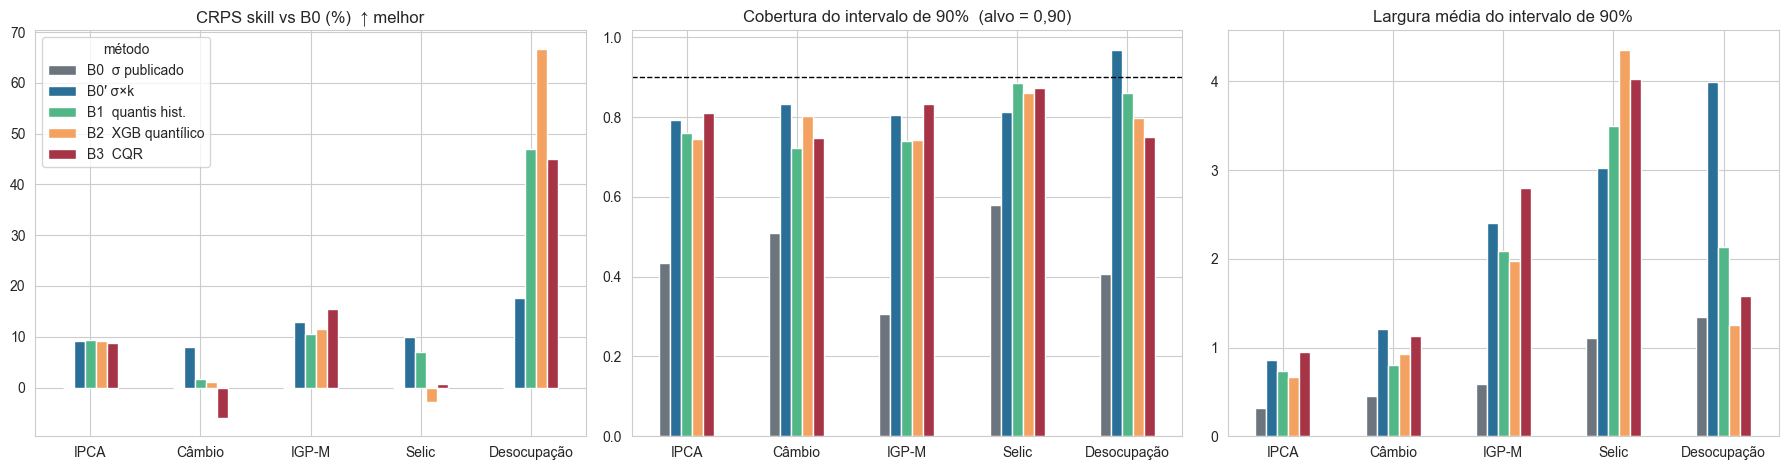

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
cores = {"B0": "#6c757d", "B0k": "#2a6f97", "B1": "#52b788", "B2": "#f4a261", "B3": "#a63446"}
inv = {v: k for k, v in NOME_METODO.items()}
ind = [ROTULO[n] for n in ORDEM if ROTULO[n] in set(tabela["indicador"])]

for ax, col, titulo in [(axes[0], "skill vs B0 (%)", "CRPS skill vs B0 (%)  ↑ melhor"),
                        (axes[1], "cobertura 90%", "Cobertura do intervalo de 90%  (alvo = 0,90)"),
                        (axes[2], "largura 90%", "Largura média do intervalo de 90%")]:
    piv = tabela.pivot(index="indicador", columns="método", values=col).loc[ind]
    piv = piv[[NOME_METODO[m] for m in METODOS if NOME_METODO[m] in piv.columns]]
    piv.plot(kind="bar", ax=ax, color=[cores[inv[c]] for c in piv.columns], legend=(col == "skill vs B0 (%)"))
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    if col == "cobertura 90%":
        ax.axhline(0.90, color="black", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

**Leitura.** O maior salto está entre **B0 e B0′**: só reescalar o σ do Focus eleva a cobertura de 90% de 30–58% para ~80% e melhora o CRPS em 8–13%. Os degraus seguintes acrescentam pouco ou nada — e, no Câmbio (CQR, −6%) e na Selic (XGBoost, −3%), chegam a piorar. Um degrau que aumenta a largura para ganhar cobertura **sem** melhorar o CRPS não está agregando informação, só trocando nitidez por calibração.

**Dois pontos que a tabela expõe:**

- **Nenhum método atinge 90% de cobertura marginal**, nem o CQR (75–87%). O B0′ foi ajustado para minimizar o pinball ao longo de toda a grade, não para acertar o nível de 90%; e o CQR, que deveria garantir o nominal, não o entrega — sintoma da violação de permutabilidade discutida na introdução, e não um bug (os testes de cobertura de `conformal.py` passam em dados permutáveis).
- **A Desocupação está na tabela, mas deve ser ignorada.** São 64 linhas — 16 datas distintas empilhadas em 4 horizontes — e os "ganhos" de +47% e +67% vêm de um único período de queda monotônica. É o mesmo alerta de amostra efetiva da Etapa 4; a linha permanece para não esconder o resultado, sem valor inferencial.

## 3. Cada degrau se paga? Diebold-Mariano entre degraus consecutivos

Testamos, sobre o **CRPS por observação**, se cada degrau supera o anterior. `d̄ > 0` favorece o degrau mais complexo. Usamos HAC com `maxlags = h−1` e a correção de Harvey-Leybourne-Newbold (`src/focus/dm_test.py`), e aplicamos a mesma regra de **amostra efetiva** da Etapa 4: com `n/h < 5` o estimador HAC degenera e o p-valor não é evidência.

In [5]:
PARES = [("B0", "B0k", "σ publicado → σ reescalado"),
         ("B0k", "B1", "σ reescalado → quantis históricos"),
         ("B0k", "B2", "σ reescalado → XGB quantílico"),
         ("B0k", "B3", "σ reescalado → CQR")]


def dm_pares():
    linhas = []
    for n in ORDEM:
        r = escada[n]
        metodos, mask = amostra_comum(n)
        if mask.sum() == 0:
            continue
        ordem = np.argsort(r["datas"].to_numpy()[mask])
        for a, b, rotulo in PARES:
            if a not in metodos or b not in metodos:
                continue
            for h in HORIZONTES_MESES:
                sel = (r["h"][mask] == h)
                idx = np.flatnonzero(sel)
                if len(idx) < 10:
                    continue
                idx = idx[np.argsort(r["datas"].to_numpy()[mask][idx])]
                y = r["y"][mask][idx]
                ca = crps_por_linha(y, r["Q"][a][mask][idx], TAUS)
                cb = crps_por_linha(y, r["Q"][b][mask][idx], TAUS)
                dm = diebold_mariano(ca, cb, h=h)          # d > 0: b (mais complexo) melhor
                linhas.append({"indicador": ROTULO[n], "degrau": rotulo, "horizonte": h, "n": len(idx),
                               "melhora %": 100 * (1 - cb.mean() / ca.mean()),
                               "p_valor": dm["p_valor"], "confiavel": len(idx) / h >= 5})
    return pd.DataFrame(linhas)


dm = dm_pares()
dm["sinal"] = np.where(~dm["confiavel"], "†",
              np.where(dm["p_valor"] >= 0.05, "n.s.",
              np.where(dm["melhora %"] > 0, "melhora", "piora")))
resumo = dm.groupby(["degrau", "sinal"]).size().unstack(fill_value=0)
for c in ("melhora", "n.s.", "piora", "†"):
    if c not in resumo.columns:
        resumo[c] = 0
display(resumo[["melhora", "n.s.", "piora", "†"]])
print("† = amostra efetiva insuficiente (n/h < 5), ignorada. Esperado por acaso a 5%: ~5% das células em cada direção.")

sinal,melhora,n.s.,piora,†
degrau,,,,
σ publicado → σ reescalado,12,6,0,2
σ reescalado → CQR,0,10,8,2
σ reescalado → XGB quantílico,0,14,4,2
σ reescalado → quantis históricos,0,15,3,2


† = amostra efetiva insuficiente (n/h < 5), ignorada. Esperado por acaso a 5%: ~5% das células em cada direção.


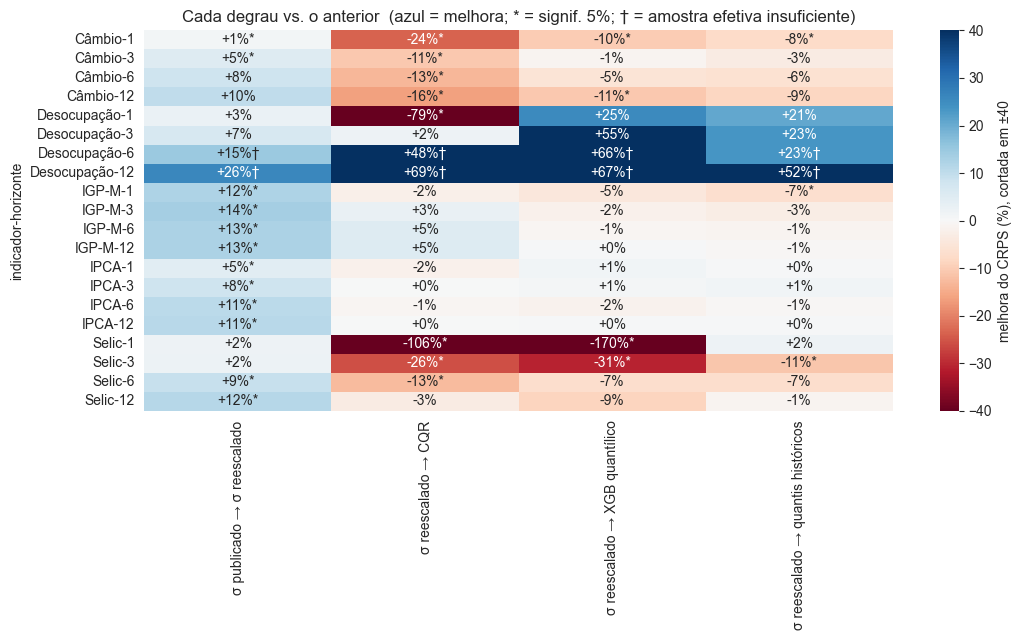

In [6]:
piv = dm.assign(ok=dm["confiavel"]).pivot_table(index=["indicador", "horizonte"], columns="degrau", values="melhora %")
fig, ax = plt.subplots(figsize=(11, 6.5))
sinal = dm.pivot_table(index=["indicador", "horizonte"], columns="degrau", values="sinal", aggfunc="first")
anot = piv.copy().astype(object)
for i in piv.index:
    for c in piv.columns:
        v = piv.loc[i, c]
        s = sinal.loc[i, c] if c in sinal.columns else ""
        anot.loc[i, c] = "" if pd.isna(v) else f"{v:+.0f}%" + ("*" if s in ("melhora", "piora") else ("†" if s == "†" else ""))
sns.heatmap(piv.clip(-40, 40), annot=anot, fmt="", cmap="RdBu", center=0, vmin=-40, vmax=40, ax=ax,
            cbar_kws={"label": "melhora do CRPS (%), cortada em ±40"})
ax.set_title("Cada degrau vs. o anterior  (azul = melhora; * = signif. 5%; † = amostra efetiva insuficiente)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 4. Robustez: o ganho sobrevive sem um único episódio?

A Etapa 4 mostrou que um ganho "significativo" do IGP-M era, na verdade, **um episódio** (2020 respondia por 58%). Aplicamos o mesmo escrutínio ao degrau que parece vencer: decompomos o ganho por ano-alvo e reestimamos excluindo os anos dominantes.

In [7]:
def ganho_por_ano(nome, a, b):
    r = escada[nome]
    metodos, mask = amostra_comum(nome)
    y = r["y"][mask]
    ganho = crps_por_linha(y, r["Q"][a][mask], TAUS) - crps_por_linha(y, r["Q"][b][mask], TAUS)   # > 0: b melhor
    ano = pd.to_datetime(r["datas"].to_numpy()[mask]).year
    return pd.DataFrame({"ano": ano, "ganho": ganho, "crps_a": crps_por_linha(y, r["Q"][a][mask], TAUS)})


resultados = []
for n in ["ipca", "cambio", "igpm", "selic"]:
    g = ganho_por_ano(n, "B0k", "B3")
    por_ano = g.groupby("ano")["ganho"].sum()
    top3 = por_ano.nlargest(3)
    linha = {"indicador": ROTULO[n], "todos os anos": 100 * g["ganho"].mean() / g["crps_a"].mean()}
    for rot, excl in [("sem 2020", [2020]), ("sem 2020–2021", [2020, 2021])]:
        m = ~g["ano"].isin(excl)
        linha[rot] = 100 * g.loc[m, "ganho"].mean() / g.loc[m, "crps_a"].mean()
    linha["top-3 anos (% do ganho)"] = 100 * top3.sum() / por_ano.sum() if por_ano.sum() != 0 else np.nan
    resultados.append(linha)

print("B3 (CQR) vs. B0′ (σ reescalado): melhora % do CRPS")
display(pd.DataFrame(resultados).set_index("indicador").round(1))

B3 (CQR) vs. B0′ (σ reescalado): melhora % do CRPS


,todos os anos,sem 2020,sem 2020–2021,top-3 anos (% do ganho)
indicador,,,,
IPCA,-0.4,-1.1,-3.5,-683.7
Câmbio,-15.1,-15.3,-16.0,-5.9
IGP-M,3.1,1.7,0.6,112.4
Selic,-10.2,-12.2,-11.6,-13.4


**Como ler.** Em IPCA, Câmbio e Selic o CQR é **pior** que o σ reescalado já com todos os anos (−0,4%, −15%, −10%), então a coluna "top-3 anos" não tem interpretação (a soma do ganho é negativa ou próxima de zero — os percentuais absurdos são artefato dessa divisão). O único caso em que o CQR parece vencer é o **IGP-M** (+3,1%) — e é exatamente o padrão da Etapa 4: o ganho concentra-se em poucos anos (top-3 = 112% do total, ou seja, os demais anos somam negativo) e cai para +1,7% sem 2020 e +0,6% sem 2020–2021. **Um ganho de 0,6% não é uma regra estável.**

## 5. Cobertura por regime — o teste que importa

A cobertura *marginal* esconde onde o intervalo falha. A pergunta relevante para quem usa a projeção é: **o intervalo continua calibrado justamente quando a economia vira?** Definimos *regimes de virada* **a priori** (não escolhidos olhando os resultados): a pandemia e o aperto pós-COVID (2020–2022) e o pivot de 2026 — os mesmos regimes destacados na Etapa 3.

In [8]:
def eh_virada(d):
    d = pd.Timestamp(d)
    return (pd.Timestamp("2020-01-01") <= d <= pd.Timestamp("2022-12-31")) or d >= pd.Timestamp("2026-01-01")


linhas = []
for n in ["ipca", "cambio", "igpm", "selic"]:
    r = escada[n]
    metodos, mask = amostra_comum(n)
    y = r["y"][mask]
    virada = np.array([eh_virada(x) for x in r["datas"].to_numpy()[mask]])
    for m in [x for x in metodos if x in ("B0", "B0k", "B1", "B3")]:
        q = r["Q"][m][mask]
        linhas.append({
            "indicador": ROTULO[n], "método": NOME_METODO[m],
            "marginal": cobertura(y, q[:, J05], q[:, J95]),
            "regime calmo": cobertura(y[~virada], q[~virada, J05], q[~virada, J95]),
            "regime de virada": cobertura(y[virada], q[virada, J05], q[virada, J95]),
            "n virada": int(virada.sum()),
        })
cob_reg = pd.DataFrame(linhas)
cob_reg["queda (p.p.)"] = 100 * (cob_reg["regime calmo"] - cob_reg["regime de virada"])
display(cob_reg.set_index(["indicador", "método"]).round(3))

marginal  regime calmo  regime de virada  \
indicador método                                                        
IPCA      B0  σ publicado       0.435         0.471             0.335   
          B0′ σ×k               0.792         0.860             0.608   
          B1  quantis hist.     0.759         0.824             0.580   
          B3  CQR               0.809         0.870             0.642   
Câmbio    B0  σ publicado       0.509         0.510             0.506   
          B0′ σ×k               0.832         0.843             0.801   
          B1  quantis hist.     0.723         0.764             0.608   
          B3  CQR               0.748         0.723             0.818   
IGP-M     B0  σ publicado       0.306         0.312             0.290   
          B0′ σ×k               0.806         0.837             0.722   
          B1  quantis hist.     0.741         0.820             0.523   
          B3  CQR               0.832         0.882             0.693   
Selic     B0  σ publicado       0.579         0.602             0.517   
          B0′ σ×k               0.813         0.849             0.717   
          B1  quantis hist.     0.885         0.917             0.800   
          B3  CQR               0.874         0.923             0.742   

                             n virada  queda (p.p.)  
indicador método                                     
IPCA      B0  σ publicado         176        13.585  
          B0′ σ×k                 176        25.155  
          B1  quantis hist.       176        24.483  
          B3  CQR                 176        22.779  
Câmbio    B0  σ publicado         176         0.465  
          B0′ σ×k                 176         4.184  
          B1  quantis hist.       176        15.651  
          B3  CQR                 176        -9.504  
IGP-M     B0  σ publicado         176         2.221  
          B0′ σ×k                 176        11.519  
          B1  quantis hist.       176        29.752  
          B3  CQR                 176        18.905  
Selic     B0  σ publicado         120         8.519  
          B0′ σ×k                 120        13.210  
          B1  quantis hist.       120        11.667  
          B3  CQR                 120        18.117

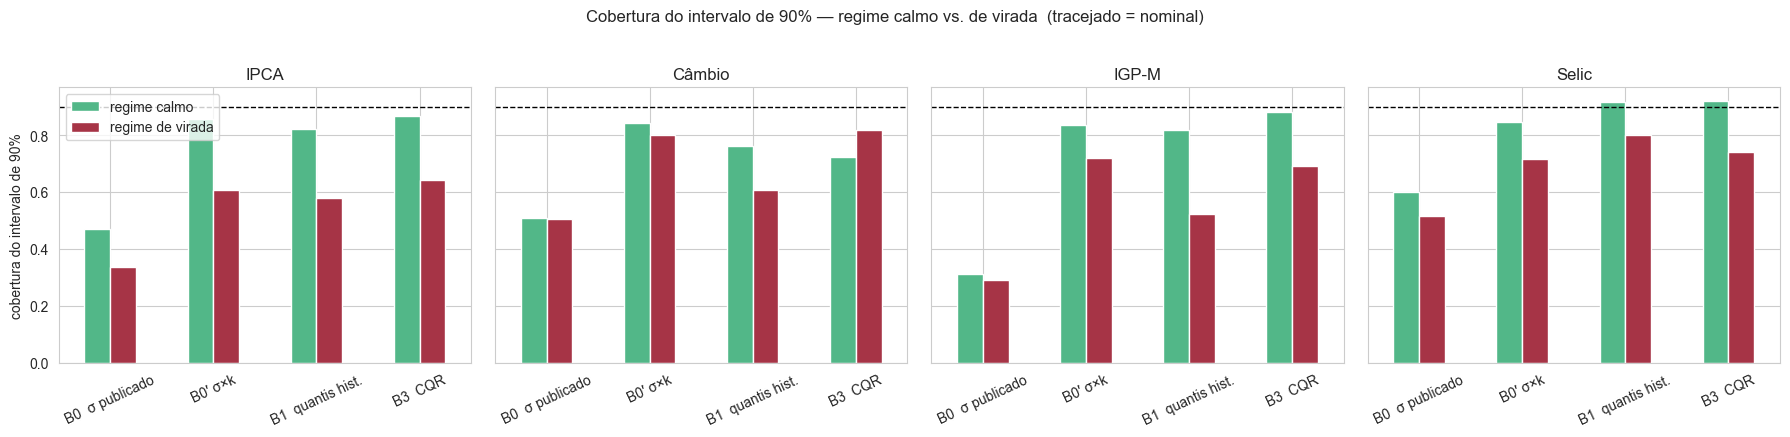

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, n in zip(axes, ["ipca", "cambio", "igpm", "selic"]):
    sub = cob_reg[cob_reg["indicador"] == ROTULO[n]].set_index("método")[["regime calmo", "regime de virada"]]
    sub.plot(kind="bar", ax=ax, color=["#52b788", "#a63446"], legend=(n == "ipca"))
    ax.axhline(0.90, color="black", linestyle="--", linewidth=1)
    ax.set_title(ROTULO[n])
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
axes[0].set_ylabel("cobertura do intervalo de 90%")
plt.suptitle("Cobertura do intervalo de 90% — regime calmo vs. de virada  (tracejado = nominal)", y=1.03)
plt.tight_layout()
plt.show()

**Este é o resultado central da seção.** Em **três dos quatro indicadores** (IPCA, IGP-M, Selic), *todos* os degraus perdem cobertura em regime de virada — inclusive o **CQR**, cuja "garantia" é apenas marginal. O σ reescalado (B0′) cai de 86% para 61% no IPCA (−25 p.p.), de 84% para 72% no IGP-M e de 85% para 72% na Selic; o CQR cai de 87% para 64%, 88% para 69% e 92% para 74%. A **exceção é o Câmbio**, onde a cobertura praticamente não muda entre regimes (B0′: −4 p.p.; CQR: +10 p.p.) — coerente com um passeio aleatório, cuja incerteza não depende do regime do Copom.

O mecanismo provável é a violação de permutabilidade — o intervalo é calibrado com erros passados, e quando o regime muda o erro fica maior que o histórico —, mas **isto é uma hipótese consistente com os dados, não algo que o notebook isolou**. O fato empírico é mais simples e vale por si: a garantia do conformal vale na média, e a média esconde onde ela falha.

## 6. Adaptive Conformal Inference: resolve a deriva?

O ACI (Gibbs & Candès, 2021) foi desenhado para exatamente este problema: em vez de um nível `α` fixo, ajusta `α_t` online — sobe quando o intervalo cobriu demais, desce quando cobriu de menos. Há uma sutileza essencial em previsão: a previsão feita hoje para um alvo daqui a `h` meses só tem o desfecho conhecido **depois**, então `α_t` só pode incorporar erros de previsões cujo alvo **já se realizou** naquele instante (`src/focus/conformal.py`, com teste explícito de ausência de vazamento). Aplicamos o ACI ao intervalo de 90%, por horizonte, com γ = 0,05.

In [10]:
def rodar_aci(nome, gamma):
    r = escada[nome]
    n = len(r["y"])
    lo, hi = np.full(n, np.nan), np.full(n, np.nan)
    lo_st, hi_st = np.full(n, np.nan), np.full(n, np.nan)
    for h in HORIZONTES_MESES:
        regs = [c for c in r["aci"] if c["h"] == h]
        if not regs:
            continue
        idx = np.concatenate([c["idx_te"] for c in regs])
        q_i = np.concatenate([c["q_inf"] for c in regs])
        q_s = np.concatenate([c["q_sup"] for c in regs])
        grupo = np.concatenate([np.full(len(c["idx_te"]), c["fold"]) for c in regs])
        escores = {c["fold"]: c["escores"] for c in regs}

        l, u, _ = aci_intervalos(q_i, q_s, r["y"][idx], escores,
                                 r["t_dec"].to_numpy()[idx], r["datas"].to_numpy()[idx],
                                 alpha=0.10, gamma=gamma, grupo=grupo)
        lo[idx], hi[idx] = l, u
        Qst = np.array([quantil_conformal(escores[g], 0.10) for g in grupo])
        lo_st[idx], hi_st[idx] = q_i - Qst, q_s + Qst
    return lo, hi, lo_st, hi_st


linhas = []
for n in ["ipca", "cambio", "igpm", "selic"]:
    r = escada[n]
    lo, hi, lo_s, hi_s = rodar_aci(n, gamma=0.05)
    ok = np.isfinite(lo) & np.isfinite(lo_s) & np.isfinite(hi) & np.isfinite(hi_s)
    y = r["y"][ok]
    virada = np.array([eh_virada(x) for x in r["datas"].to_numpy()[ok]])
    for rotulo, (l, u) in {"CQR estático": (lo_s, hi_s), "ACI (γ=0,05)": (lo, hi)}.items():
        l, u = l[ok], u[ok]
        linhas.append({
            "indicador": ROTULO[n], "método": rotulo, "n": int(ok.sum()),
            "marginal": cobertura(y, l, u),
            "regime calmo": cobertura(y[~virada], l[~virada], u[~virada]),
            "regime de virada": cobertura(y[virada], l[virada], u[virada]),
            "largura": float(np.mean(u - l)),
        })
tab_aci = pd.DataFrame(linhas)
display(tab_aci.set_index(["indicador", "método"]).round(3))

n  marginal  regime calmo  regime de virada  largura
indicador método                                                              
IPCA      CQR estático  469     0.814         0.853             0.698    0.931
          ACI (γ=0,05)  469     0.876         0.895             0.819    1.069
Câmbio    CQR estático  416     0.817         0.814             0.828    1.064
          ACI (γ=0,05)  416     0.858         0.845             0.899    1.129
IGP-M     CQR estático  387     0.822         0.863             0.695    2.762
          ACI (γ=0,05)  387     0.832         0.863             0.737    3.042
Selic     CQR estático  353     0.901         0.972             0.731    3.421
          ACI (γ=0,05)  353     0.861         0.944             0.663    3.246

**Resultado: o ACI ajuda onde há deriva de escala, e piora onde não há.**

- **IPCA:** a cobertura em virada sobe de 70% para 82% (marginal 81% → 88%), ao custo de ~15% mais largura.
- **Câmbio:** 83% → 90% em virada, marginal 82% → 86%.
- **IGP-M:** ganho pequeno (69% → 74% em virada), com largura ~10% maior.
- **Selic: piora.** A marginal cai de 90% para 86% e a de virada de 73% para 66%.

A Selic é o caso instrutivo. Em regime calmo o CQR estático **sobre-cobre** (97%) — 76% dos erros de `h=1` são exatamente zero —, e o ACI reage a esse excesso **estreitando** o intervalo. Quando o regime vira, ele já está apertado demais. O ACI assume que a cobertura passada informa sobre a cobertura futura; numa série com longos períodos de erro nulo seguidos de surpresas grandes, isso é falso, e a "adaptação" trabalha contra.

**Nenhuma variante atinge 90% em regime de virada** (o melhor caso, Câmbio, chega a 90%; os demais ficam em 66–82%). O ACI reduz a lacuna; não a fecha.

## 7. Conclusões

**A melhor alternativa probabilística ao Focus, com a evidência disponível, é a mais simples: o próprio σ do Focus, reescalado por um fator `k(indicador, horizonte)` estimado no histórico (B0′).**

**Por que B0′ e não algo mais sofisticado:**

1. **É o único degrau com ganho robusto.** Sobre o σ publicado, o B0′ melhora o CRPS em **8–13%** nos quatro indicadores com amostra suficiente (IPCA +9,1%, Câmbio +7,9%, IGP-M +12,9%, Selic +10,0%) e leva a cobertura do intervalo de 90% de 31–58% para 79–83%. No Diebold-Mariano, **12 de 16 células (indicador × horizonte) melhoram e nenhuma piora** nos quatro indicadores com amostra suficiente: IPCA e IGP-M em todos os 4 horizontes, Câmbio e Selic em 2 de 4 (o restante é não significativo). A Desocupação contribui com zero melhoras e é excluída da contagem.
2. **Nada acima dele se paga.** Sobre o B0′: quantis históricos (0 melhoras, 3 pioras), XGBoost quantílico (0 melhoras, 4 pioras) e CQR (0 melhoras, 8 pioras). O único aparente vencedor, o CQR no IGP-M (+3,1%), cai para +0,6% sem 2020–2021 — o mesmo episódio que sustentava o ganho aparente da Etapa 4.
3. **O modelo condicional não encontra sinal.** O XGBoost quantílico frequentemente para em zero iterações (nenhuma melhora na validação): condicionar a largura do intervalo ao estado macro, com estas features e esta amostra, não supera a largura por indicador × horizonte.

**O que isso diz sobre o Focus.** A dispersão publicada é **informativa** (ordena bem a incerteza relativa — Etapa 3) e **mal escalada**. Um fator multiplicativo estimado no histórico, sem nenhum modelo, recupera a maior parte do valor. O Focus não precisa ser substituído; precisa de uma **régua de conversão** entre a discordância dos analistas e a incerteza real.

**O que continua sem solução — e é o achado mais importante para quem usa a projeção:**

- **Em regime de virada, nenhum método fica calibrado.** O intervalo de 90% do B0′ cobre 61% (IPCA), 72% (IGP-M) e 72% (Selic) nesses períodos; o CQR, 64–74%. O ACI reduz a lacuna no IPCA e no Câmbio, mas **piora** na Selic. Um usuário que confie num intervalo "de 90%" justamente quando a política monetária vira estará, na prática, com um intervalo de ~60–75%.
- **A garantia de cobertura do conformal não se materializa nesta série** (75–87% marginal, contra 90% nominal), como esperado dada a violação de permutabilidade.
- **A Câmbio é a exceção informativa:** sua cobertura é estável entre regimes, coerente com um passeio aleatório.

**Ressalvas:** (i) a Desocupação não pode ser avaliada (16 datas independentes); (ii) os regimes de virada foram definidos *a priori* (2020–2022 e 2026), mas 2026 tem poucas observações; (iii) hiperparâmetros do XGBoost fixos e conservadores — não é prova de que nenhum modelo condicional funcione, só de que este não superou o baseline simples; (iv) `k` é estimado com a grade de quantis inteira, não para acertar um nível específico.

### Consequência para o plano

O plano original previa o **CQR como entrega final** e um SHAP sobre a **largura** do intervalo condicional (Etapa 6). Os resultados **não sustentam** nenhum dos dois: o CQR não bate o baseline simples, e não há largura condicional aprendida para explicar. A Etapa 6, como desenhada, explicaria um modelo que não agrega valor.